> **Historical notebook:** the reproducible current workflow is `src/pipeline.py` and `src/train_model.py`.
> The final Random Forest results are recorded in the last section of this notebook.

# Clinical Score Training

Combine healthy controls (ground truth 0) with workbook-scored Parkinsonian recordings and evaluate a participant-grouped train/test split.


In [1]:
from pathlib import Path
import csv
import openpyxl
import numpy as np

ROOT = Path.cwd()
required = [ROOT / "Clinical Score.xlsx", ROOT / "data/features/recording_level_features.csv"]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError("Supply the local clinical workbook and feature table: " + ", ".join(missing))

with (ROOT / "data/features/recording_level_features.csv").open(newline="") as handle:
    rows = list(csv.DictReader(handle))

book = openpyxl.load_workbook(ROOT / "Clinical Score.xlsx", data_only=True, read_only=True)
scores = {}
for sheet in book.worksheets:
    participant = {"A_PD001": "Atypical_PD001"}.get(sheet.title, sheet.title)
    scores[participant] = {
        int(str(row[0]).split(".")[0]): float(row[3])
        for row in sheet.iter_rows(min_row=4, max_row=36, values_only=True)
        if row[0] and row[3] is not None
    }

print(f"Recordings: {len(rows)}")
print("Diagnosis counts:", {d: sum(r["diagnosis"] == d for r in rows) for d in sorted({r["diagnosis"] for r in rows})})
print("Participant counts:", {p: sum(r["participant_id"] == p for r in rows) for p in sorted({r["participant_id"] for r in rows})})
print("Clinician Part III totals:", {p: sum(items.values()) for p, items in scores.items()})

Recordings: 29
Diagnosis counts: {'Atypical Parkinsonism': 2, 'Healthy': 12, "Parkinson's Disease": 15}
Participant counts: {'Atypical_PD001': 2, 'HP001': 4, 'HP002': 4, 'HP003': 4, 'PD001': 4, 'PD002': 11}
Clinician Part III totals: {'PD001': 50.0, 'PD002': 28.0, 'Atypical_PD001': 101.0}


## Features and labels

Task-to-score mapping is provisional.


In [2]:
TASK_SCORE_ITEM = {
    "Arm Extended Forward": 21, "Finger Tapping": 11, "Finger to Nose": 21,
    "Hand Resting": 6, "Fist Open and Close": 12, "Pronation Supination": 13,
    "Normal Walking": 16, "Quiet Standing": 17, "Sit-to-Stand": 15, "TUG": 15,
}

labeled = []
for source in rows:
    item = TASK_SCORE_ITEM.get(source["task"])
    if source["participant_id"] in scores and item in scores[source["participant_id"]]:
        row = dict(source)
        row["clinical_score"] = scores[source["participant_id"]][item]
        row["mapped_item"] = item
        labeled.append(row)

META = {
    "recording_id", "participant_id", "diagnosis", "session_id", "task", "file_path",
    "file_type", "sensor_side", "sensor_location", "signal_column_used", "quality_status",
    "quality_warnings", "clinical_score", "clinical_score_source", "label_verified",
    "mapped_item", "recording_duration_s", "sampling_rate_hz",
}
numeric_names = []
for name in labeled[0]:
    if name in META:
        continue
    try:
        [float(row[name]) for row in labeled if row[name] != ""]
        numeric_names.append(name)
    except (ValueError, TypeError):
        pass

def matrix(records):
    return np.array([[float(row.get(name, "") or np.nan) for name in numeric_names] for row in records], dtype=float)

healthy = []
for source in rows:
    if source["diagnosis"] == "Healthy":
        row = dict(source)
        row["clinical_score"] = 0.0
        row["mapped_item"] = "Healthy cohort ground truth"
        healthy.append(row)

combined = labeled + healthy
X = matrix(combined)
y = np.array([row["clinical_score"] for row in combined], dtype=float)
groups = np.array([row["participant_id"] for row in combined])

print(f"Combined ground-truth labels: {len(combined)} / {len(rows)} recordings")
print("Combined labels by participant:", {str(p): int(sum(groups == p)) for p in sorted(set(groups))})
print(f"Healthy rows assigned ground truth 0: {len(healthy)}")
print(f"Numeric features: {len(numeric_names)}")

Combined ground-truth labels: 28 / 29 recordings
Combined labels by participant: {'Atypical_PD001': 2, 'HP001': 4, 'HP002': 4, 'HP003': 4, 'PD001': 4, 'PD002': 10}
Healthy rows assigned ground truth 0: 12
Numeric features: 77


In [3]:
from collections import Counter

print("Data statistics")
print(f"Total recordings: {len(rows)}")
print(f"Workbook-scored Parkinsonian: {len(labeled)} | Healthy ground-truth: {len(healthy)}")
print(f"Features: {len(numeric_names)}")
print("Diagnosis:", dict(Counter(row["diagnosis"] for row in rows)))
print("Score distribution:", {int(score): int(count) for score, count in Counter(y.astype(int)).items()})
print("Missing feature values:", int(np.isnan(X).sum()), "of", X.size)

Data statistics
Total recordings: 29
Workbook-scored Parkinsonian: 16 | Healthy ground-truth: 12
Features: 77
Diagnosis: {'Healthy': 12, 'Atypical Parkinsonism': 2, "Parkinson's Disease": 15}
Score distribution: {3: 2, 2: 2, 1: 12, 0: 12}
Missing feature values: 824 of 2156


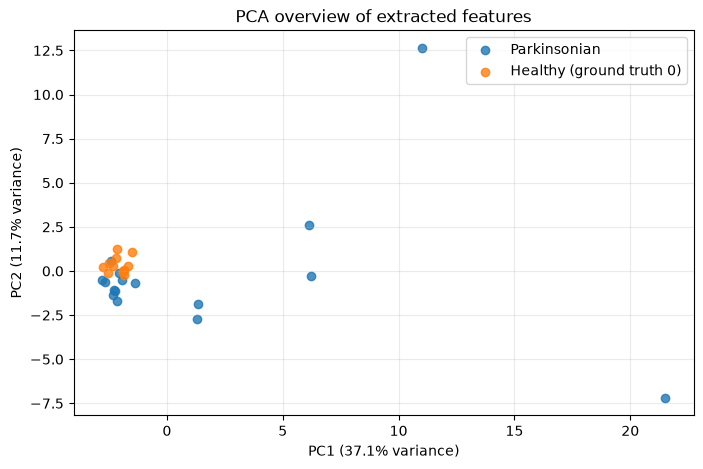

PCA variance explained: PC1=0.371, PC2=0.117


In [4]:
import matplotlib.pyplot as plt

# PCA on imputed, standardized features for a 2D data overview.
all_features = X.copy()
pca_medians = np.zeros(all_features.shape[1])
for index in range(all_features.shape[1]):
    valid = all_features[:, index][np.isfinite(all_features[:, index])]
    pca_medians[index] = np.median(valid) if len(valid) else 0.0
all_features = np.where(np.isfinite(all_features), all_features, pca_medians)
all_features = (all_features - all_features.mean(0)) / np.maximum(all_features.std(0), 1e-12)
_, singular_values, components = np.linalg.svd(all_features, full_matrices=False)
projection = all_features @ components[:2].T
variance = singular_values**2 / np.sum(singular_values**2)

plt.figure(figsize=(8, 5))
healthy_mask = np.array([row["diagnosis"] == "Healthy" for row in combined])
plt.scatter(projection[~healthy_mask, 0], projection[~healthy_mask, 1], label="Parkinsonian", alpha=0.8)
plt.scatter(projection[healthy_mask, 0], projection[healthy_mask, 1], label="Healthy (ground truth 0)", alpha=0.8)
plt.xlabel(f"PC1 ({variance[0] * 100:.1f}% variance)")
plt.ylabel(f"PC2 ({variance[1] * 100:.1f}% variance)")
plt.title("PCA overview of extracted features")
plt.legend()
plt.grid(alpha=0.25)
plt.show()
print(f"PCA variance explained: PC1={variance[0]:.3f}, PC2={variance[1]:.3f}")

## Train and validate

Train on all workbook-scored unhealthy recordings and evaluate a held-out healthy participant, comparing a baseline with training-only jitter-bootstrap augmentation.


In [5]:
def impute_scale(train, test):
    medians = np.zeros(train.shape[1])
    for index in range(train.shape[1]):
        valid = train[:, index][np.isfinite(train[:, index])]
        medians[index] = np.median(valid) if len(valid) else 0.0
    train = np.where(np.isfinite(train), train, medians)
    test = np.where(np.isfinite(test), test, medians)
    mean, scale = train.mean(0), train.std(0)
    scale[scale < 1e-12] = 1.0
    return (train - mean) / scale, (test - mean) / scale

def fit_ridge(train, target, alpha=10.0):
    design = np.column_stack([np.ones(len(train)), train])
    penalty = alpha * np.eye(design.shape[1])
    penalty[0, 0] = 0
    return np.linalg.solve(design.T @ design + penalty, design.T @ target)

def predict_ridge(weights, features):
    return np.clip(np.column_stack([np.ones(len(features)), features]) @ weights, 0, 4)

def ridge_predict(train, target, test, alpha=10.0):
    train, test = impute_scale(train, test)
    return predict_ridge(fit_ridge(train, target, alpha), test)

def mae(actual, predicted):
    return float(np.mean(np.abs(actual - predicted)))

def rmse(actual, predicted):
    return float(np.sqrt(np.mean((actual - predicted) ** 2)))

# Train on all workbook-scored unhealthy rows and hold out one healthy participant.
unhealthy = labeled
healthy_by_participant = {}
for row in healthy:
    healthy_by_participant.setdefault(row["participant_id"], []).append(row)
split_rng = np.random.default_rng(42)
healthy_test_participant = str(split_rng.choice(sorted(healthy_by_participant)))
healthy_test = healthy_by_participant[healthy_test_participant]
healthy_train = [row for participant, records in healthy_by_participant.items() if participant != healthy_test_participant for row in records]
X_unhealthy = matrix(unhealthy)
y_unhealthy = np.array([row["clinical_score"] for row in unhealthy], dtype=float)
X_healthy_test = matrix(healthy_test)
y_healthy_test = np.zeros(len(healthy_test), dtype=float)
assert set(row["participant_id"] for row in unhealthy).isdisjoint({healthy_test_participant})

def augment_features(train, target, repeats=4, noise_scale=0.02, seed=42):
    """Bootstrap labeled rows and add small feature-relative Gaussian jitter."""
    rng = np.random.default_rng(seed)
    medians = np.array([np.nanmedian(train[:, index]) if np.isfinite(train[:, index]).any() else 0.0 for index in range(train.shape[1])])
    imputed = np.where(np.isfinite(train), train, medians)
    feature_scale = np.maximum(np.std(imputed, axis=0), 1e-6)
    sampled = rng.integers(0, len(imputed), size=len(imputed) * repeats)
    augmented = imputed[sampled] + rng.normal(0.0, noise_scale * feature_scale, size=(len(sampled), imputed.shape[1]))
    return np.vstack([imputed, augmented]), np.concatenate([target, target[sampled]])

baseline_prediction = ridge_predict(X_unhealthy, y_unhealthy, X_healthy_test)
X_augmented, y_augmented = augment_features(X_unhealthy, y_unhealthy)
augmented_prediction = ridge_predict(X_augmented, y_augmented, X_healthy_test)

def report_metrics(actual, predicted):
    rounded = np.rint(predicted).astype(int)
    return {
        "mae": mae(actual, predicted),
        "rmse": rmse(actual, predicted),
        "accuracy": float(np.mean(rounded == actual.astype(int))),
    }

print("Training participants:", sorted(set(row["participant_id"] for row in unhealthy)))
print("Held-out healthy participant:", healthy_test_participant)
print("Training rows:", len(X_unhealthy), "| Augmented training rows:", len(X_augmented), "| Test rows:", len(X_healthy_test))
print("No augmentation metrics:", report_metrics(y_healthy_test, baseline_prediction))
print("Jitter-bootstrap metrics:", report_metrics(y_healthy_test, augmented_prediction))


Training participants: ['Atypical_PD001', 'PD001', 'PD002']
Held-out healthy participant: HP001
Training rows: 16 | Augmented training rows: 80 | Test rows: 4
No augmentation metrics: {'mae': 0.9747711081397745, 'rmse': 1.1290128040580008, 'accuracy': 0.25}
Jitter-bootstrap metrics: {'mae': 1.5516741622042791, 'rmse': 2.154943822371142, 'accuracy': 0.25}


## Augmentation comparison

All unhealthy recordings are used for training. One healthy participant is held out for testing; healthy ground truth is 0.


In [6]:
# Compare augmented and non-augmented models on the same held-out healthy rows.
assert len(unhealthy) == 16 and len(healthy) == 12
print("All unhealthy rows used for training:", len(unhealthy))
print("Held-out healthy rows used for testing:", len(healthy_test))
print("Held-out healthy ground truth:", set(y_healthy_test.astype(int)))
print("No augmentation predictions:", np.round(baseline_prediction, 3).tolist())
print("Jitter-bootstrap predictions:", np.round(augmented_prediction, 3).tolist())


All unhealthy rows used for training: 16
Held-out healthy rows used for testing: 4
Held-out healthy ground truth: {np.int64(0)}
No augmentation predictions: [1.37, 1.373, 0.0, 1.156]
Jitter-bootstrap predictions: [1.368, 4.0, 0.0, 0.838]


## Train versus test comparison

Descriptive feature and prediction comparisons.


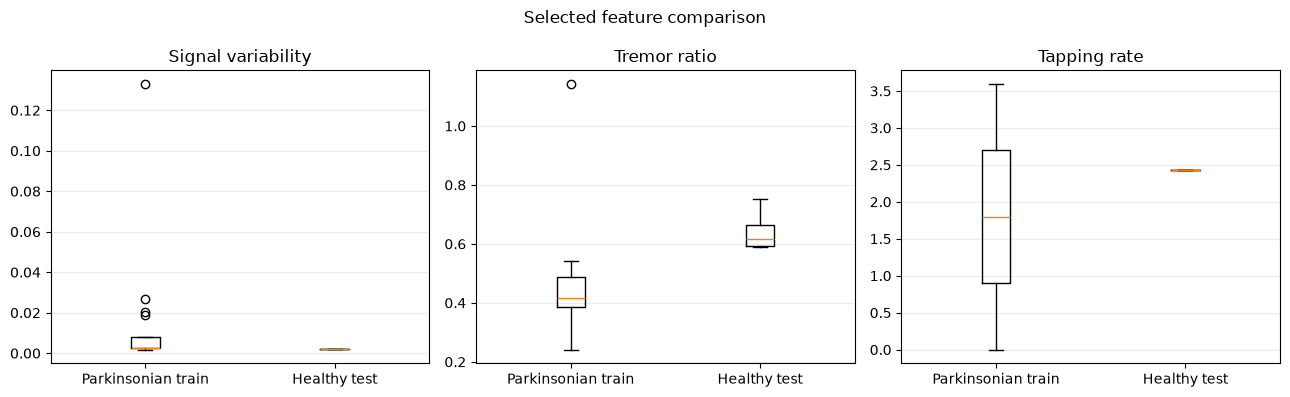

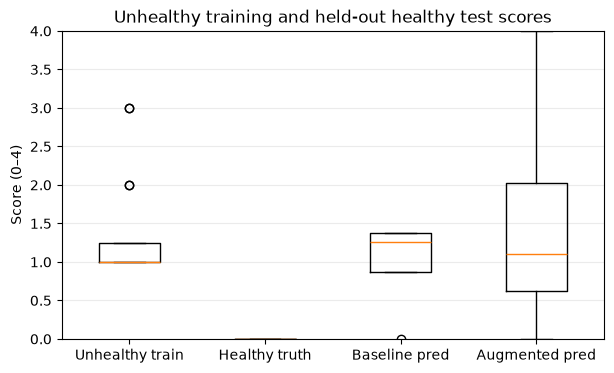

Healthy controls use the explicitly defined ground truth of 0; augmentation is training-only.


In [7]:
import matplotlib.pyplot as plt

selected = [("signal_std", "Signal variability"), ("tremor_power_ratio", "Tremor ratio"), ("tap_rate_hz", "Tapping rate")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for axis, (feature, label) in zip(axes, selected):
    index = numeric_names.index(feature)
    axis.boxplot([X_unhealthy[:, index][np.isfinite(X_unhealthy[:, index])], X_healthy_test[:, index][np.isfinite(X_healthy_test[:, index])]], tick_labels=["Parkinsonian train", "Healthy test"])
    axis.set_title(label)
    axis.grid(axis="y", alpha=0.25)
fig.suptitle("Selected feature comparison")
fig.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.boxplot([y_unhealthy, y_healthy_test, baseline_prediction, augmented_prediction], tick_labels=["Unhealthy train", "Healthy truth", "Baseline pred", "Augmented pred"])
plt.ylim(0, 4)
plt.ylabel("Score (0–4)")
plt.title("Unhealthy training and held-out healthy test scores")
plt.grid(axis="y", alpha=0.25)
plt.show()
print("Healthy controls use the explicitly defined ground truth of 0; augmentation is training-only.")

## Summary

- Jitter-bootstrap augmentation is applied only to the 16 unhealthy training rows.
- The held-out healthy participant uses the cohort ground truth of 0.
- Augmentation did not improve this single healthy-participant holdout.
- The dataset is small and the task-to-score mapping needs clinician confirmation.

## Current Random Forest training result

The active training workflow was run on 10 November 2026 using the regenerated 50-recording dataset. It uses a Random Forest classifier, median imputation, 78 numeric features, and 5-fold GroupKFold validation grouped by participant.

| Metric | Result |
|---|---:|
| Participants | 9 |
| Recordings | 50 |
| MAE | 0.560 |
| RMSE | 1.020 |
| Ordinal accuracy | 68.0% |
| Macro-F1 | 0.279 |
| Pearson correlation | 0.599 |
| Predictions in 0–4 range | 100% |

The trained model and exact metrics are saved in `reports/model/best_model.joblib` and `reports/model/metrics.json`; out-of-fold predictions are in `reports/model/oof_predictions.csv`. These are exploratory results, not clinical validation. Score 4 has no examples in the current labels, so performance for that class cannot be assessed.
